# NeAr lamp wavelength calibration

This script helps to calibrate the LISA Spectrometer NeAr lamp, and is intended to be used at the calibration step, when Demetra fails the automatic calibration procedure.

This will find emission lines in a 1D NeAr lamp profile, matches them to a list of known wavelengths, and fits

$$\lambda(p) = A_0 + A_1 p + A_2 p^2 + \dots + A_n p^n$$

so the coefficients can be typed back into Demetra.

## Instructions:

1. Upload the list of LISA lines (exported from Demetra) and the spectrum you want to calibrate to the Colab environment here (folder icon on left bar -> upload, and the spectrum you want is \<object>_Calibration_S.fit, which is created right before the calibration step).
2. Enter those file names in Cell 2. If you want to play with the parameters, do that here too.
3. Run the script!
4. Check the result, and if it looks good enter the A's into Demetra's calibration routine and continue your work.

## Copyright

This script is licensed under GNU General Public License v3.0, authored by Christopher L Duston. Last updated 20261029.

## 1. Imports
Everything here ships with Colab already, so no installs are needed.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.modeling import models, fitting
from astropy.stats import sigma_clip
from scipy.signal import find_peaks
from scipy.ndimage import median_filter

plt.rcParams['figure.figsize'] = (14, 4.5)
plt.rcParams['figure.dpi'] = 100

## 2. User parameters
All the knobs live here. Defaults are reasonable starting points for a NeAr lamp; you'll most likely only touch the first block.

In [ ]:
# ---- Files -----------------------------------------------------------------
FITS_FILE     = 'Muliphen_Calibration_S.fit'
#'Findstest_NeAr_lamp.fits'   # 1D lamp profile
LINELIST_FILE = 'LISA.txt'
#'NeAr_lines.txt'        # one wavelength (Angstrom) per line; '#' comments allowed

# Do you want to create and download a file with the wavelength calibration info?
DOWNLOAD_FLAG = 0

# ---- What you roughly know about the setup -------------------------------
LAMBDA_FIRST_PIX = 3600.0   # approx. wavelength at the first pixel (A)
LAMBDA_LAST_PIX  = 7200.0   # approx. wavelength at the last pixel (A); can be smaller than FIRST if the spectrum is flipped
POLY_ORDER       = 4        # order n of the final polynomial
PIXEL_ORIGIN     = 0        # 0 -> first pixel is p=0 ; 1 -> first pixel is p=1 (check against Demetra!)

# ---- Optional: 2D input ---------------------------------------------------
# Is not by default Demetra behavior
ROWS_TO_SUM = None          # only used if the FITS is a 2D image: (row_start, row_stop) to sum; None = all rows

# ---- Continuum removal ----------------------------------------------------
# really needs inspection, or routine to manage it
CONTINUUM_WINDOW = 100       # px, running-median width; must be several times wider than a line - default 51

# ---- Peak finding ---------------------------------------------------------
PEAK_PROMINENCE_FRAC = 0.004 # keep peaks whose prominence > this fraction of the brightest line - default 0.02
PEAK_MIN_SEPARATION  = 4    # px, peaks closer than this are treated as one
PEAK_MIN_WIDTH       = 1.0  # px, rejects single-pixel spikes (hot pixels, cosmics)

# ---- Gaussian centroiding -------------------------------------------------
FIT_HALF_WIDTH = 5          # px either side of each peak used in the Gaussian fit, was 6. Generally should be 2-3 x FMHW
MAX_CENTROID_SHIFT = 2.0    # px, reject fits whose centre wanders further than this from the raw peak

# ---- Matching -------------------------------------------------------------
SHIFT_SEARCH_RANGE = 200   # A, how far to slide the rough guess when looking for the best alignment, deafult 70
DISPERSION_SEARCH_FRAC = 0.15  # how far to stretch/squeeze the rough dispersion (0.08 = +-8%), default 0.08
MATCH_TOL_INITIAL  = 6.0    # A, matching tolerance using the rough linear guess
MATCH_TOL_FINAL    = 1.5    # A, matching tolerance once we have a real fit

# ---- Fitting --------------------------------------------------------------
CLIP_SIGMA = 3.0            # sigma-clipping threshold for outlier matches
CLIP_ITERS = 3

## 3. Get the files into Colab
In Colab, if the files aren't already in the session, this cell opens an upload dialog. Pick **both** the `.fits` and the `.txt` file. Make sure the names match `FITS_FILE` and `LINELIST_FILE` above. Outside Colab it just checks the files exist.

In [ ]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

missing = [f for f in (FITS_FILE, LINELIST_FILE) if not os.path.exists(f)]
if missing and IN_COLAB:
    print('Missing:', missing, '-> please upload them')
    uploaded = colab_files.upload()
    missing = [f for f in (FITS_FILE, LINELIST_FILE) if not os.path.exists(f)]

if missing:
    raise FileNotFoundError(f'Still missing {missing}. Files present: {os.listdir(".")}')
print('Found', FITS_FILE, 'and', LINELIST_FILE)

Found Muliphen_Calibration_S.fit and LISA.txt


## 4. Load the lamp spectrum
We take the first HDU that contains data. If it's 2D, we sum rows to make a profile (this is not usual behavior for Demetra, and would require ensuring proper calibration and off-spectra background removal). The header is printed so you can see if Demetra already wrote a (possibly bad) wavelength solution into it (`CRVAL1`, `CDELT1`).

Filename: Muliphen_Calibration_S.fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      39   (1391,)   float32   
NAXIS1   = 1391
CRVAL1   = 0
CDELT1   = 1
DATE-OBS = 2026-09-25T00:30:45.998


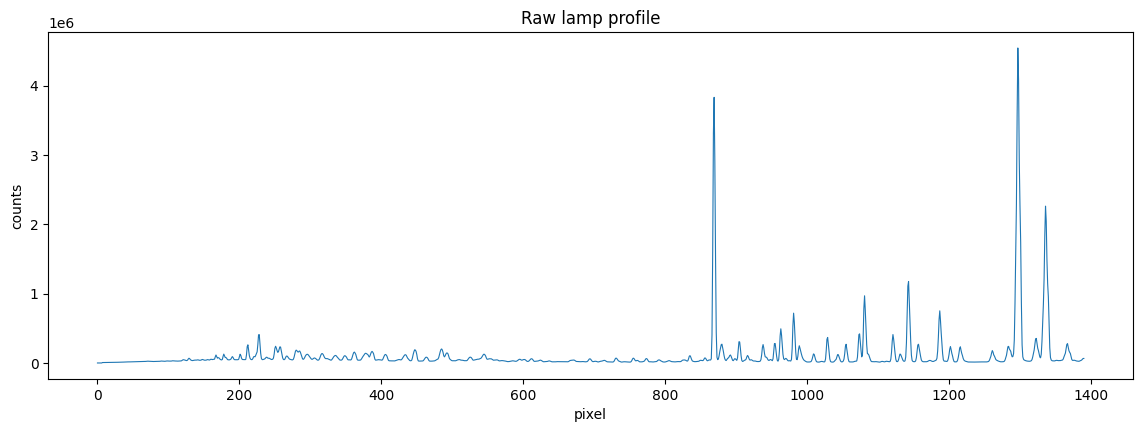

1391 pixels, p runs 0 .. 1390


In [ ]:
hdul = fits.open(FITS_FILE)
hdul.info()

data = None
for hdu in hdul:
    if hdu.data is not None:
        data = np.asarray(hdu.data, dtype=float)
        header = hdu.header
        break
hdul.close()

data = np.squeeze(data)
if data.ndim == 2:
    r0, r1 = ROWS_TO_SUM if ROWS_TO_SUM is not None else (0, data.shape[0])
    print(f'2D image {data.shape}: summing rows {r0}:{r1}')
    flux = data[r0:r1].sum(axis=0)
elif data.ndim == 1:
    flux = data
else:
    raise ValueError(f'Unexpected data shape {data.shape}')

n_pix = flux.size
pix = np.arange(n_pix) + PIXEL_ORIGIN       # pixel coordinate used everywhere below

for key in ('NAXIS1', 'CRVAL1', 'CDELT1', 'CRPIX1', 'CTYPE1', 'OBJECT', 'DATE-OBS'):
    if key in header:
        print(f'{key:8s} = {header[key]}')

plt.plot(pix, flux, lw=0.8)
plt.xlabel('pixel'); plt.ylabel('counts'); plt.title('Raw lamp profile')
plt.show()
print(f'{n_pix} pixels, p runs {pix[0]} .. {pix[-1]}')

## 5. Remove the continuum
A running median that's much wider than a line follows the smooth background and ignores the narrow lines. Subtracting it leaves lines sitting on roughly zero, which makes "prominence" mean the same thing across the whole spectrum.

*If lines get eaten (dips appear under strong lines), increase `CONTINUUM_WINDOW`.*

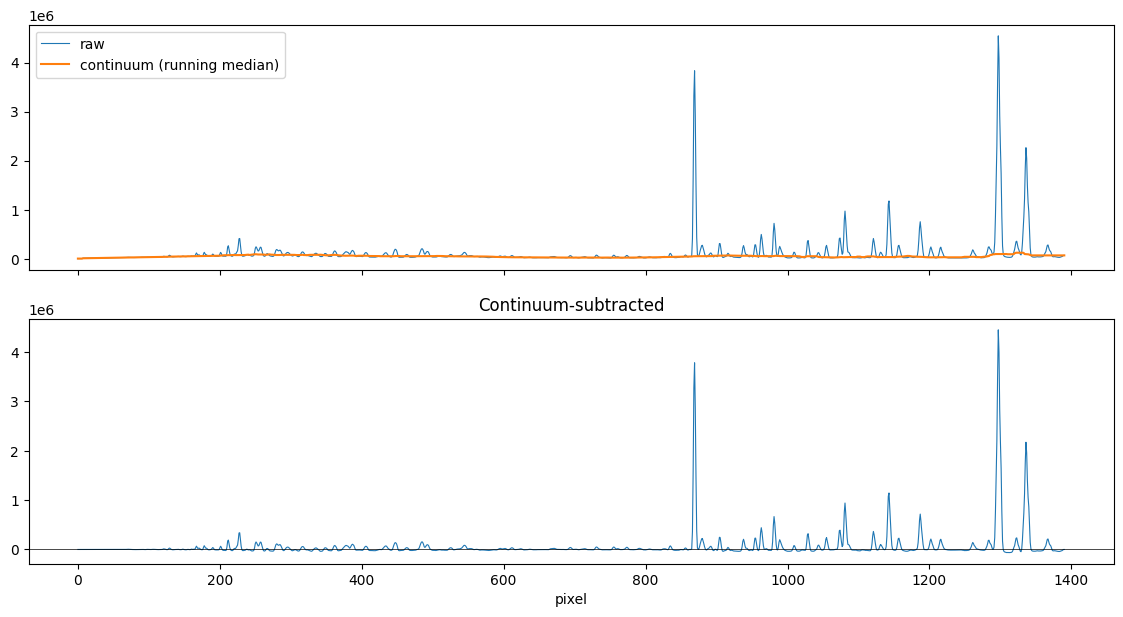

Noise (MAD) ~ 22916.63 counts


In [ ]:
continuum = median_filter(flux, size=CONTINUUM_WINDOW, mode='nearest')
flux_sub = flux - continuum

# robust noise estimate from the line-free part: median absolute deviation
noise = 1.4826 * np.median(np.abs(flux_sub - np.median(flux_sub)))

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(pix, flux, lw=0.8, label='raw')
ax[0].plot(pix, continuum, lw=1.5, label='continuum (running median)')
ax[0].legend()
ax[1].plot(pix, flux_sub, lw=0.8)
ax[1].axhline(0, color='k', lw=0.5)
ax[1].set_xlabel('pixel'); ax[1].set_title('Continuum-subtracted')
plt.show()
print(f'Noise (MAD) ~ {noise:.2f} counts')

## 6. Find candidate peaks
`scipy.signal.find_peaks` keeps local maxima that pass three tests:
- **prominence** (how far the peak rises above its surroundings) > `PEAK_PROMINENCE_FRAC` × brightest line,
- **separation** ≥ `PEAK_MIN_SEPARATION` px,
- **width** ≥ `PEAK_MIN_WIDTH` px (kills hot pixels).

It's fine to find *more* peaks than are in your list. Unknown lines just won't match. Too few peaks is the real problem.

*Missing obvious lines → lower `PEAK_PROMINENCE_FRAC`. Lots of noise spikes → raise it.*

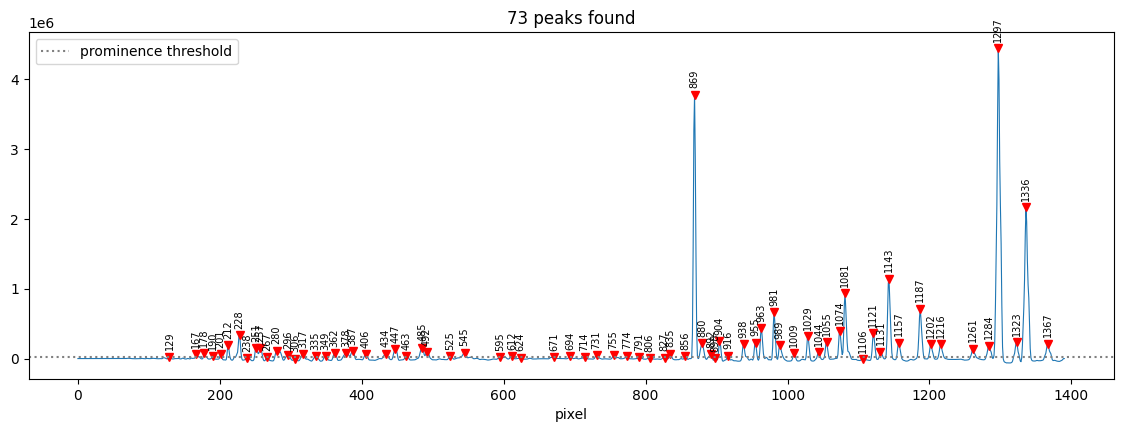

In [ ]:
prom_threshold = PEAK_PROMINENCE_FRAC * np.max(flux_sub)
peak_idx, peak_props = find_peaks(flux_sub,
                                  prominence=prom_threshold,
                                  distance=PEAK_MIN_SEPARATION,
                                  width=PEAK_MIN_WIDTH)

plt.plot(pix, flux_sub, lw=0.8)
plt.plot(pix[peak_idx], flux_sub[peak_idx], 'rv', ms=6)
for i in peak_idx:
    plt.annotate(f'{pix[i]}', (pix[i], flux_sub[i]), textcoords='offset points',
                 xytext=(0, 6), ha='center', fontsize=7, rotation=90)
plt.axhline(prom_threshold, color='gray', ls=':', label='prominence threshold')
plt.xlabel('pixel'); plt.title(f'{len(peak_idx)} peaks found'); plt.legend()
plt.show()

## 7. Sub-pixel centroids (Gaussian fits)
The raw peak is only good to ±0.5 px. Fitting a Gaussian + constant over ±`FIT_HALF_WIDTH` px gives the centre to a small fraction of a pixel. That matters, because at ~1 Å/px a 0.3 px error is a 0.3 Å error.

A fit is rejected if it fails, comes out with negative amplitude, or its centre wanders more than `MAX_CENTROID_SHIFT` px from the raw peak (that usually means a blend or a neighbour). The grid below shows every fit. Glance through it.

72 of 73 peaks gave good Gaussian fits
median FWHM = 4.38 px


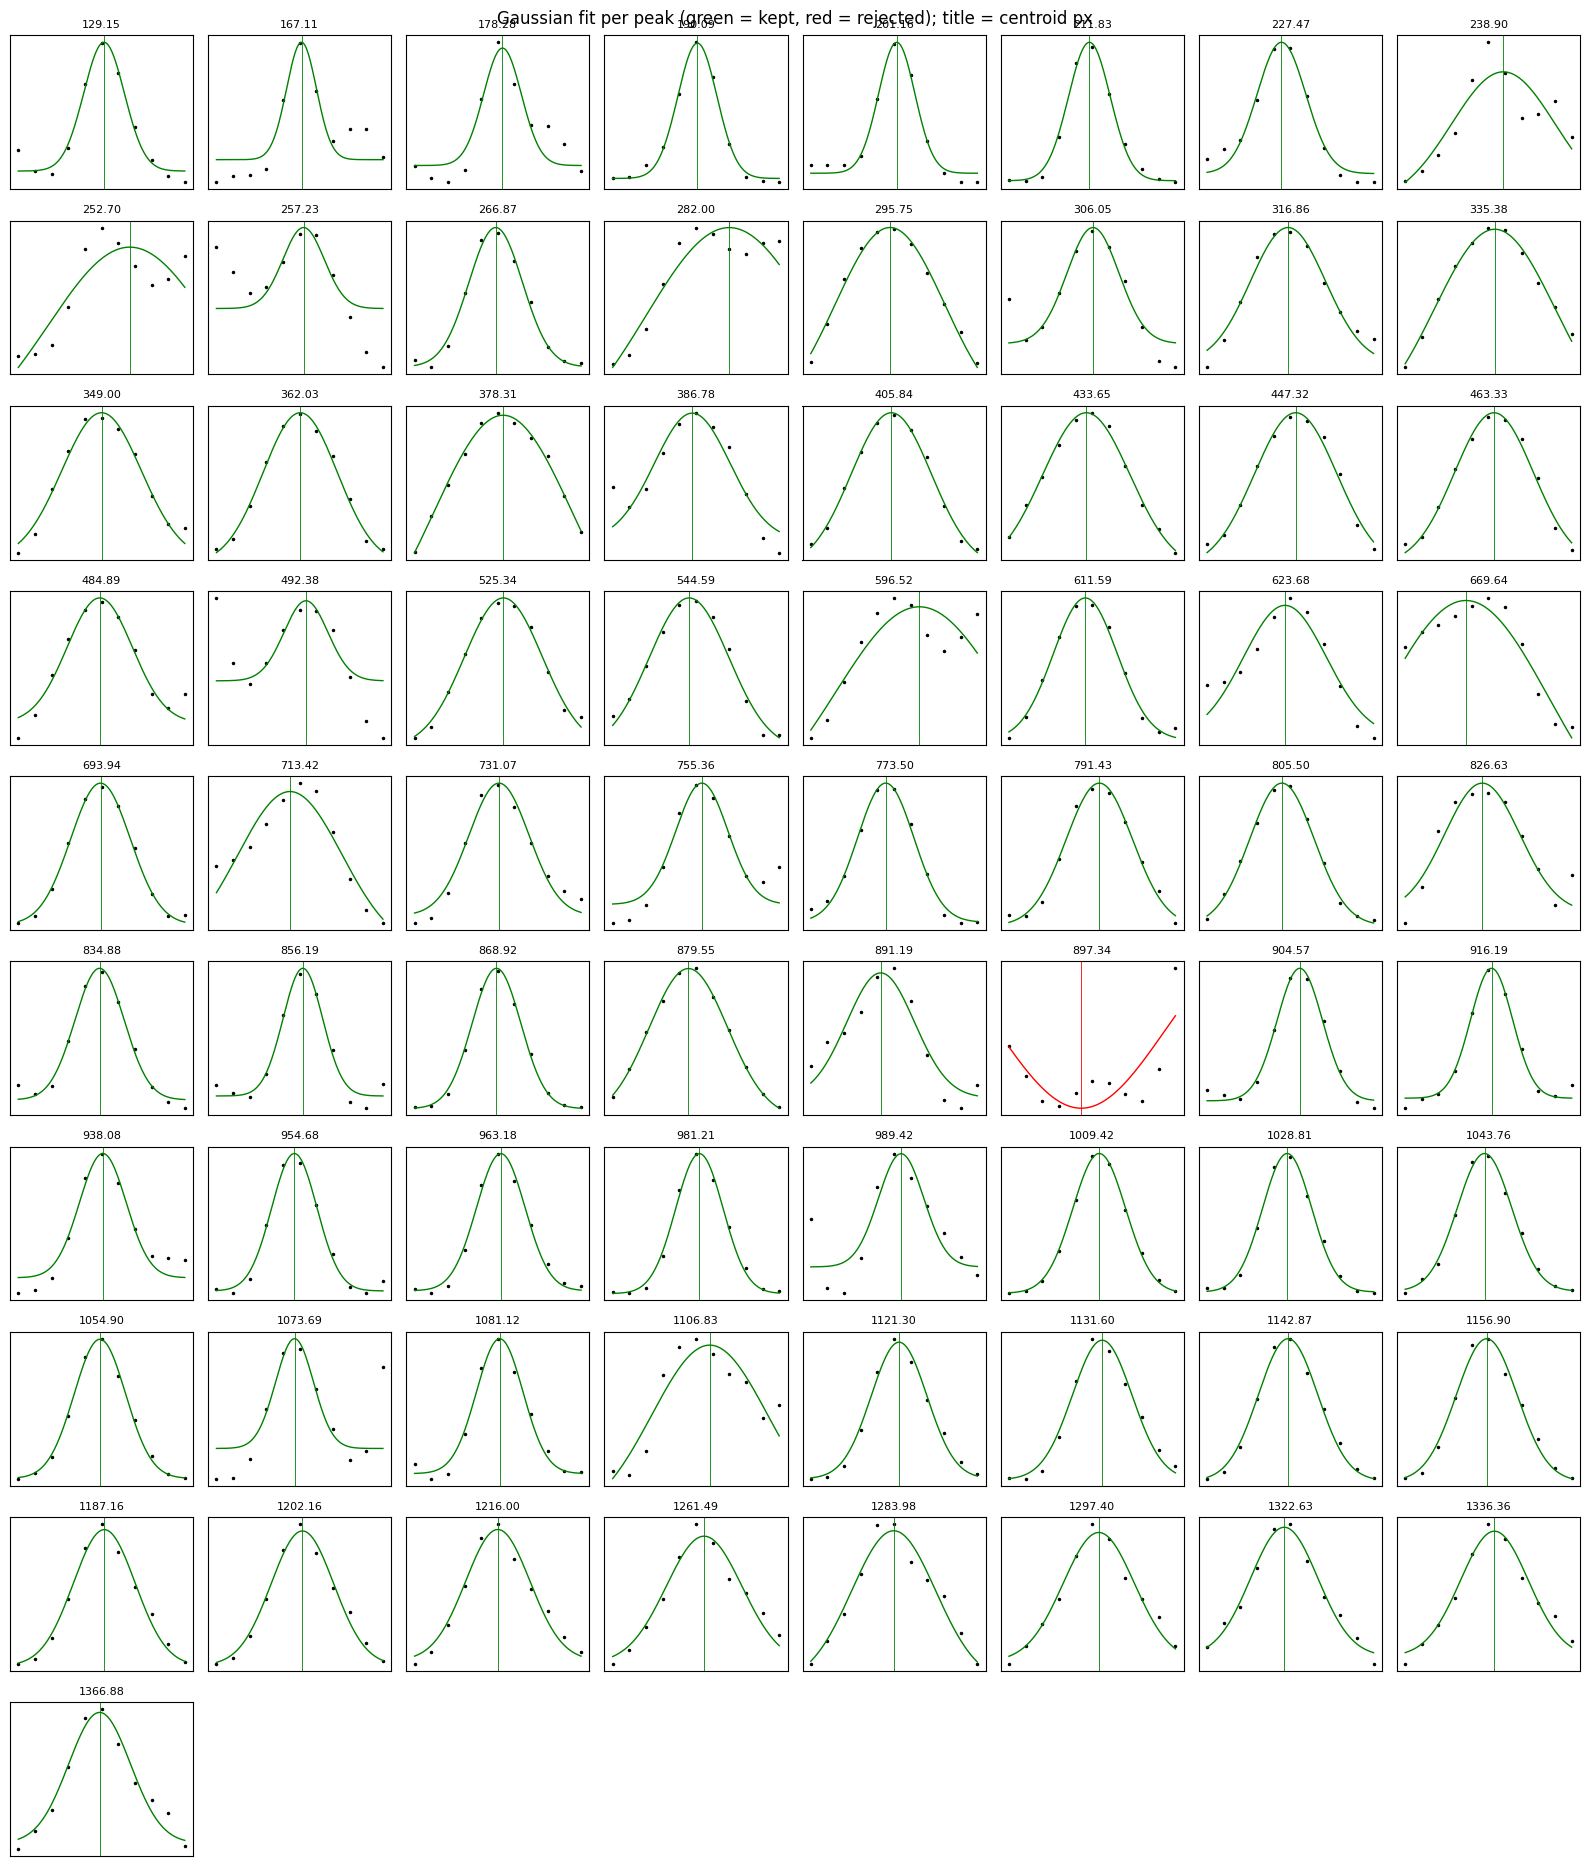

In [ ]:
fitter = fitting.TRFLSQFitter()

centroids, fwhms, amps, keep_idx = [], [], [], []
fit_records = []   # for plotting

for i in peak_idx:
    lo, hi = max(0, i - FIT_HALF_WIDTH), min(n_pix, i + FIT_HALF_WIDTH + 1)
    x, y = pix[lo:hi].astype(float), flux_sub[lo:hi]

    g0 = models.Gaussian1D(amplitude=flux_sub[i], mean=pix[i], stddev=1.5) + models.Const1D(0.0)
    g0.mean_0.bounds = (pix[i] - MAX_CENTROID_SHIFT, pix[i] + MAX_CENTROID_SHIFT)
    g0.stddev_0.bounds = (0.3, FIT_HALF_WIDTH)
    try:
        g = fitter(g0, x, y)
    except Exception as e:
        print(f'pixel {pix[i]}: fit failed ({e})')
        continue

    ok = (g.amplitude_0.value > 0) and (abs(g.mean_0.value - pix[i]) < MAX_CENTROID_SHIFT)
    fit_records.append((x, y, g, ok, pix[i]))
    if ok:
        centroids.append(g.mean_0.value)
        fwhms.append(2.3548 * g.stddev_0.value)
        amps.append(g.amplitude_0.value)

centroids, fwhms, amps = map(np.array, (centroids, fwhms, amps))
print(f'{len(centroids)} of {len(peak_idx)} peaks gave good Gaussian fits')
print(f'median FWHM = {np.median(fwhms):.2f} px')

ncol = 8
nrow = int(np.ceil(len(fit_records) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 1.9 * nrow), squeeze=False)
for ax, (x, y, g, ok, p0) in zip(axes.flat, fit_records):
    xf = np.linspace(x[0], x[-1], 200)
    ax.plot(x, y, 'k.', ms=3)
    ax.plot(xf, g(xf), 'g-' if ok else 'r-', lw=1)
    ax.axvline(g.mean_0.value, color='g' if ok else 'r', lw=0.6)
    ax.set_title(f'{g.mean_0.value:.2f}', fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(fit_records):]:
    ax.axis('off')
plt.suptitle('Gaussian fit per peak (green = kept, red = rejected); title = centroid px')
plt.tight_layout(); plt.show()

## 8. Load the line list and make the rough guess
From your two rough endpoint wavelengths we build a straight line, λ ≈ λ_first + D·(p − p_first), and convert every centroid to an approximate wavelength. The catalog lines are drawn on top. They won't line up perfectly yet, and that's expected.

  skipped line 1: 'Name:LISA|Instrument:Lisa'
Wavelengths read: [3946.0971 4158.5907 4510.733  4545.0519 4609.5673 4657.9012 4764.8646
 4879.8646 4965.0795 5187.7462 5400.5617 5495.8738 5764.419  6074.3377
 6163.5939 6266.495  6334.4278 6506.5281 6717.043  6871.2891 6965.4307
 7067.22   7147.0416]
23 catalog lines: 3946.10 .. 7147.04 A
Rough dispersion: 2.5899 A/px


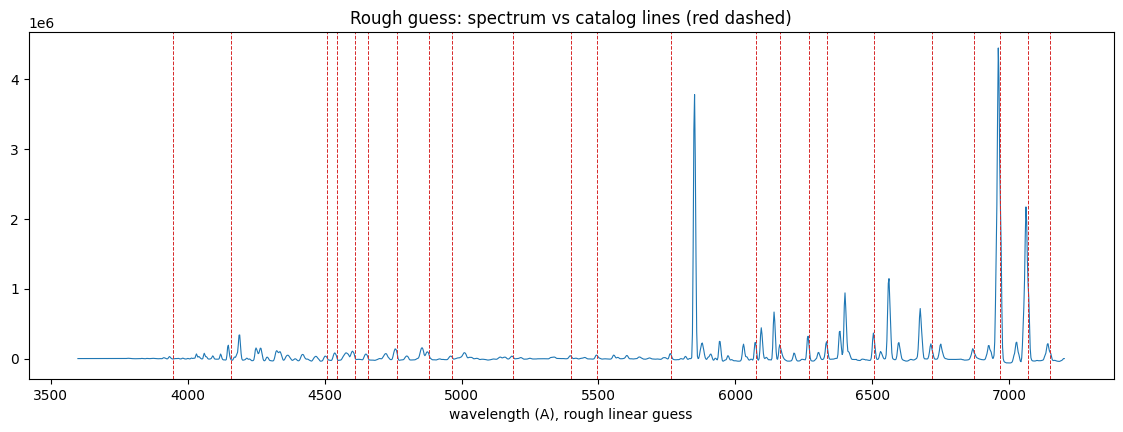

In [ ]:
import re
number_re = re.compile(r'[-+]?\d+(?:\.\d+)?')
catalog, skipped = [], []
with open(LINELIST_FILE, encoding='utf-8', errors='replace') as f:
    for n, raw in enumerate(f, start=1):
        line = raw.strip()
        if not line or line.startswith('#'):
            continue
        # keep the first number on the line that looks like an optical wavelength in Angstrom
        wl = [float(x) for x in number_re.findall(line) if 3000 <= float(x) <= 12000]
        if wl:
            catalog.append(wl[0])
        else:
            skipped.append((n, line))
catalog = np.sort(np.array(catalog))

for n, line in skipped:
    print(f'  skipped line {n}: {line!r}')
if catalog.size == 0:
    raise ValueError('No wavelengths between 3000 and 12000 A found in the line list. Is it in nm instead of A?')
print('Wavelengths read:', catalog)
print(f'{catalog.size} catalog lines: {catalog.min():.2f} .. {catalog.max():.2f} A')

D_guess = (LAMBDA_LAST_PIX - LAMBDA_FIRST_PIX) / (pix[-1] - pix[0])   # A/px, sign handles flipped spectra
p_mid = 0.5 * (pix[0] + pix[-1])
lam_mid = 0.5 * (LAMBDA_FIRST_PIX + LAMBDA_LAST_PIX)

def lambda_guess(p, shift=0.0, scale=1.0):
    # straight line pivoting on the detector centre: 'shift' slides it, 'scale' stretches it
    return lam_mid + scale * D_guess * (p - p_mid) + shift

print(f'Rough dispersion: {D_guess:.4f} A/px')

lam_axis = lambda_guess(pix)
plt.plot(lam_axis, flux_sub, lw=0.8)
for c in catalog:
    plt.axvline(c, color='C3', ls='--', lw=0.7)
plt.xlabel('wavelength (A), rough linear guess'); plt.title('Rough guess: spectrum vs catalog lines (red dashed)')
plt.show()

## 9. Find the best rough alignment (shift × stretch)
Your endpoint guesses can be wrong in two ways. The whole range can be **shifted**, or it can be the wrong **width**, which means the dispersion is a bit off. A dispersion error of only 3% already smears to ~40 Å across a 1200 px detector, which ruins matching.

So we try a grid of straight lines that pivot on the detector centre:
- shift over ±`SHIFT_SEARCH_RANGE` Å,
- stretch over ±`DISPERSION_SEARCH_FRAC`.

For each we count how many catalog lines land within `MATCH_TOL_INITIAL` Å of a centroid. The true alignment is a single bright spot in the map. Several equally bright spots, or a featureless map, mean the rough range is too far off. Fix the endpoints or widen the search.

This is the "brute force but transparent" version of what packages like `rascal` do with a Hough transform.

Explaination: This wild thing is basically just changing the lines around - using both shifts and dispersion changes - and then checking the number of pixels that matched under that particular set of (shift,dispersion):

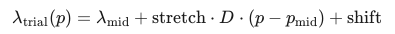



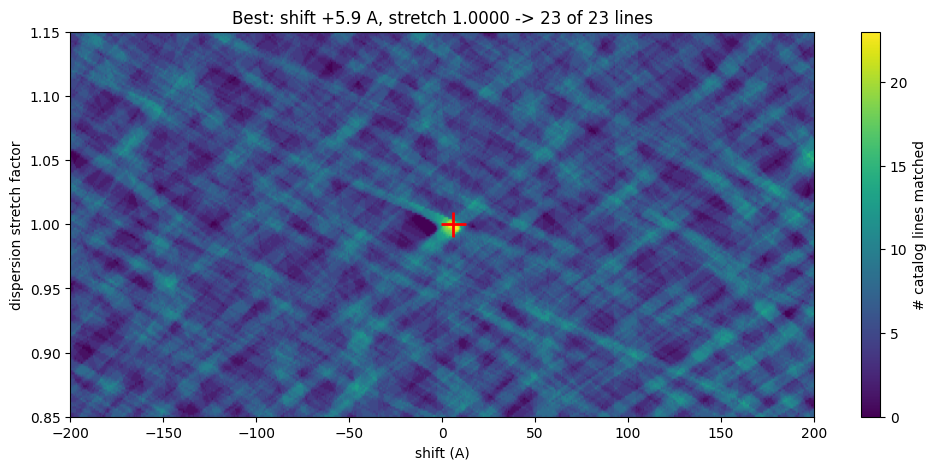

Rough solution after alignment: 3605.9 .. 7205.9 A, 2.5899 A/px


In [ ]:
shift_step = abs(D_guess) / 4
shifts = np.arange(-SHIFT_SEARCH_RANGE, SHIFT_SEARCH_RANGE + shift_step, shift_step)
# stretch step chosen so the ends of the detector move by about half the tolerance per step
half_span = 0.5 * abs(D_guess) * (pix[-1] - pix[0])
scale_step = 0.5 * MATCH_TOL_INITIAL / half_span
scales = np.arange(1 - DISPERSION_SEARCH_FRAC, 1 + DISPERSION_SEARCH_FRAC + scale_step, scale_step)

n_matches = np.zeros((scales.size, shifts.size), dtype=int)
for a, sc in enumerate(scales):
    for b, s in enumerate(shifts):
        lam_c = lambda_guess(centroids, s, sc)
        # distance from each catalog line to its nearest centroid
        dist = np.min(np.abs(catalog[:, None] - lam_c[None, :]), axis=1)
        n_matches[a, b] = np.sum(dist < MATCH_TOL_INITIAL)

# best = most matches; ties broken by the smallest change from your guess
best_count = n_matches.max()
ia, ib = np.nonzero(n_matches == best_count)
penalty = np.abs(shifts[ib]) / SHIFT_SEARCH_RANGE + np.abs(scales[ia] - 1) / DISPERSION_SEARCH_FRAC
best_scale, best_shift = scales[ia[np.argmin(penalty)]], shifts[ib[np.argmin(penalty)]]

plt.figure(figsize=(12, 5))
plt.imshow(n_matches, origin='lower', aspect='auto', cmap='viridis',
           extent=[shifts[0], shifts[-1], scales[0], scales[-1]])
plt.colorbar(label='# catalog lines matched')
plt.plot(best_shift, best_scale, 'r+', ms=18, mew=2)
plt.xlabel('shift (A)'); plt.ylabel('dispersion stretch factor')
plt.title(f'Best: shift {best_shift:+.1f} A, stretch {best_scale:.4f} -> {best_count} of {catalog.size} lines')
plt.show()
print(f'Rough solution after alignment: {lambda_guess(pix[0], best_shift, best_scale):.1f} .. '
      f'{lambda_guess(pix[-1], best_shift, best_scale):.1f} A, {best_scale*D_guess:.4f} A/px')

## 10. Iterative match → fit → re-match
Matching rule: each catalog line takes its nearest centroid within the tolerance, and no centroid may be claimed by two catalog lines (the closer one wins).

We then build up the polynomial order step by step: order 1 first, then 2, …, up to `POLY_ORDER`. After each fit we **re-match with the new, better solution**, using the tight tolerance. This picks up lines in the middle of the spectrum that the straight-line guess missed because of the curvature.

Each fit uses astropy's `FittingWithOutlierRemoval`: least-squares fit, sigma-clip residuals at `CLIP_SIGMA`, refit, repeat. Clipped lines are kept in the table but flagged.

In [ ]:
def match_lines(lam_of_centroids, tol):
    # returns arrays (catalog_index, centroid_index) of one-to-one matches within tol
    pairs = []
    for ci, c in enumerate(catalog):
        d = np.abs(lam_of_centroids - c)
        j = np.argmin(d)
        if d[j] < tol:
            pairs.append((ci, j, d[j]))
    # enforce one-to-one: if a centroid is claimed twice, keep the closest catalog line
    best = {}
    for ci, j, d in pairs:
        if j not in best or d < best[j][1]:
            best[j] = (ci, d)
    cat_i = np.array([v[0] for v in best.values()], dtype=int)
    cen_i = np.array(list(best.keys()), dtype=int)
    order = np.argsort(cat_i)
    return cat_i[order], cen_i[order]

def fit_poly_clipped(p, lam, order):
    # least-squares polynomial fit with iterative sigma clipping.
    # returns (sol, clipped): sol is a callable polynomial in p, clipped is a boolean mask.
    # np.polynomial.Polynomial.fit rescales p to [-1, 1] internally -> numerically stable at high order
    clipped = np.zeros(p.size, dtype=bool)
    for it in range(CLIP_ITERS):
        sol = np.polynomial.Polynomial.fit(p[~clipped], lam[~clipped], order)
        r = lam - sol(p)
        spread = np.std(r[~clipped])
        new_clipped = np.abs(r - np.median(r[~clipped])) > CLIP_SIGMA * spread
        if np.array_equal(new_clipped, clipped):
            break
        clipped = new_clipped
    sol = np.polynomial.Polynomial.fit(p[~clipped], lam[~clipped], order)   # final fit on the final mask
    return sol, clipped

# start: matches from the shifted rough guess
cat_i, cen_i = match_lines(lambda_guess(centroids, best_shift, best_scale), MATCH_TOL_INITIAL)
print(f'Initial match: {cat_i.size} lines')

for order in range(1, POLY_ORDER + 1):
    if cat_i.size < order + 2:
        raise RuntimeError(f'Only {cat_i.size} matches - not enough to fit order {order}. '
                           'Check the rough range / peak finding.')
    sol, clipped = fit_poly_clipped(centroids[cen_i], catalog[cat_i], order)
    resid = catalog[cat_i] - sol(centroids[cen_i])
    n_fit = (~clipped).sum()
    rms = np.sqrt(np.sum(resid[~clipped]**2) / (n_fit - (order + 1)))   # divide by degrees of freedom, not N
    print(f'order {order}: {cat_i.size} lines, {clipped.sum()} clipped, RMS = {rms:.3f} A')

    # re-match with the improved solution and the tight tolerance
    tol = MATCH_TOL_FINAL if order >= 2 else max(MATCH_TOL_FINAL, 3 * rms)
    n_before = cat_i.size
    cat_i, cen_i = match_lines(sol(centroids), tol)
    print(f'        re-matched with tol {tol:.2f} A -> {cat_i.size} lines')
    if cat_i.size < 0.7 * n_before:
        print('        WARNING: re-matching lost many lines; the previous fit was probably built on wrong matches.')

# final fit on the final match set
sol, clipped = fit_poly_clipped(centroids[cen_i], catalog[cat_i], POLY_ORDER)

# convert from the internal [-1, 1] variable to plain coefficients: lambda = A0 + A1 p + A2 p^2 + ...
coeffs = sol.convert().coef
coeffs = np.pad(coeffs, (0, POLY_ORDER + 1 - coeffs.size))   # in case trailing zeros were dropped

def wavelength(p):
    # lambda(p) = A0 + A1 p + A2 p^2 + ...   (p in the PIXEL_ORIGIN convention)
    p = np.asarray(p, dtype=float)
    return sum(coeffs[k] * p**k for k in range(coeffs.size))

conv_err = np.max(np.abs(wavelength(pix) - sol(pix)))
print(f'Plain coefficients reproduce the fit to {conv_err:.2e} A across the detector')

resid = catalog[cat_i] - wavelength(centroids[cen_i])
used = ~clipped
rms = np.sqrt(np.sum(resid[used]**2) / (used.sum() - (POLY_ORDER + 1)))   # divide by degrees of freedom, not N
print(f'\nFINAL order {POLY_ORDER}: {used.sum()} lines used, {clipped.sum()} clipped, RMS = {rms:.4f} A '
      f'({rms/abs(D_guess):.3f} px)')

Initial match: 23 lines
order 1: 23 lines, 0 clipped, RMS = 2.313 A
        re-matched with tol 6.94 A -> 23 lines
order 2: 23 lines, 0 clipped, RMS = 0.603 A
        re-matched with tol 1.50 A -> 23 lines
order 3: 23 lines, 0 clipped, RMS = 0.402 A
        re-matched with tol 1.50 A -> 23 lines
order 4: 23 lines, 0 clipped, RMS = 0.408 A
        re-matched with tol 1.50 A -> 23 lines
Plain coefficients reproduce the fit to 1.82e-12 A across the detector

FINAL order 4: 23 lines used, 0 clipped, RMS = 0.4079 A (0.157 px)


## 11. Residuals: the main quality check
- **Top:** residual (catalog − fit) per line. These should scatter randomly around zero. A smooth wave pattern means the order is too low. Wild swings at the ends with few lines there means the order is too high.
- **Bottom:** the solution minus its own linear part, so you can see how much curvature the fit is putting in.

Also, compare the fitted RMS to the scatter you'd expect. Good lamp fits are usually a small fraction of a pixel. Also, just watch the RMS as you increase the order of the polynomial - when the RMS levels out, you're not doing much better as you increase the order of the polynomial (this is essentially done in a later cell).

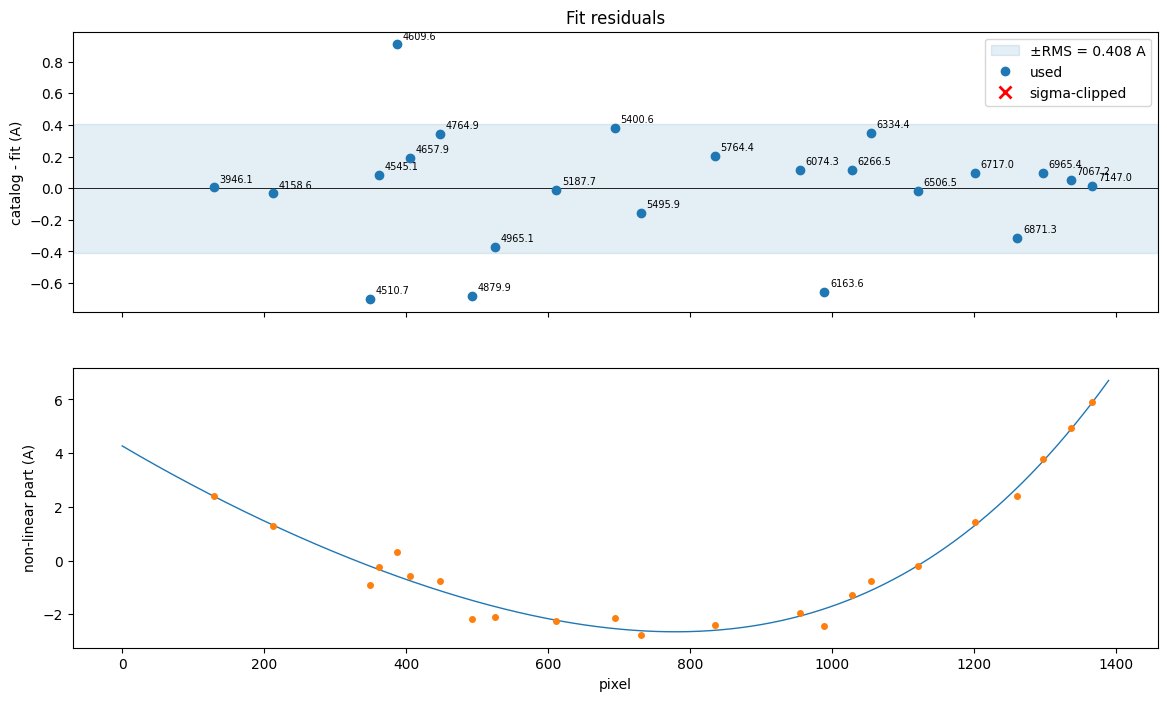

 catalog A     pixel      fit A  resid A  FWHM px  status
   3946.10   129.148   3946.093    0.004     2.87  ok
   4158.59   211.832   4158.624   -0.033     2.96  ok
   4510.73   349.000   4511.434   -0.701     5.63  ok
   4545.05   362.032   4544.970    0.082     5.25  ok
   4609.57   386.779   4608.658    0.909     5.35  ok
   4657.90   405.836   4657.711    0.190     5.67  ok
   4764.86   447.324   4764.522    0.342     5.83  ok
   4879.86   492.376   4880.547   -0.682     3.11  ok
   4965.08   525.335   4965.453   -0.374     5.51  ok
   5187.75   611.587   5187.759   -0.013     4.53  ok
   5400.56   693.937   5400.182    0.380     4.22  ok
   5495.87   731.071   5496.032   -0.158     4.26  ok
   5764.42   834.880   5764.218    0.201     3.48  ok
   6074.34   954.678   6074.221    0.116     3.20  ok
   6163.59   989.423   6164.250   -0.656     3.21  ok
   6266.49  1028.810   6266.380    0.115     3.47  ok
   6334.43  1054.900   6334.077    0.350     3.64  ok
   6506.53  1121.301   6

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax[0].axhline(0, color='k', lw=0.6)
ax[0].axhspan(-rms, rms, color='C0', alpha=0.12, label=f'±RMS = {rms:.3f} A')
ax[0].plot(centroids[cen_i][used], resid[used], 'o', label='used')
ax[0].plot(centroids[cen_i][clipped], resid[clipped], 'rx', ms=9, mew=2, label='sigma-clipped')
for p_, r_, w_ in zip(centroids[cen_i], resid, catalog[cat_i]):
    ax[0].annotate(f'{w_:.1f}', (p_, r_), textcoords='offset points', xytext=(4, 4), fontsize=7)
ax[0].set_ylabel('catalog - fit (A)'); ax[0].legend(); ax[0].set_title('Fit residuals')

lin = np.polyfit(pix, wavelength(pix), 1)
ax[1].plot(pix, wavelength(pix) - np.polyval(lin, pix), lw=1)
ax[1].plot(centroids[cen_i], catalog[cat_i] - np.polyval(lin, centroids[cen_i]), 'o', ms=4)
ax[1].set_xlabel('pixel'); ax[1].set_ylabel('non-linear part (A)')
plt.show()

print(f'{"catalog A":>10} {"pixel":>9} {"fit A":>10} {"resid A":>8} {"FWHM px":>8}  status')
for k in range(cat_i.size):
    j = cen_i[k]
    print(f'{catalog[cat_i[k]]:10.2f} {centroids[j]:9.3f} {wavelength(centroids[j]):10.3f} '
          f'{resid[k]:8.3f} {fwhms[j]:8.2f}  {"CLIPPED" if clipped[k] else "ok"}')

unmatched = np.setdiff1d(np.arange(catalog.size), cat_i)
if unmatched.size:
    print('\nCatalog lines with no match:', catalog[unmatched])

## 11b. Order selection

Runs through a few polynomial orders to find where the RMS improves.

AT THE END OF THIS CELL GIVES A RECOMMENDED POLYNOMIAL ORDER - GO BACK TO THE BEGINNING TO RESET THAT!

23 lines used

order  fit RMS (A)  LOO RMS (A)  worst LOO (A)  at line
    1       2.3127       2.4854         5.1506  7147.04
    2       0.6035       0.6878        -1.5539  3946.10
    3       0.4018       0.4220         0.9678  4609.57
    4       0.4079       0.4266         1.0763  4609.57
    5       0.4187       0.4479         1.0733  4609.57


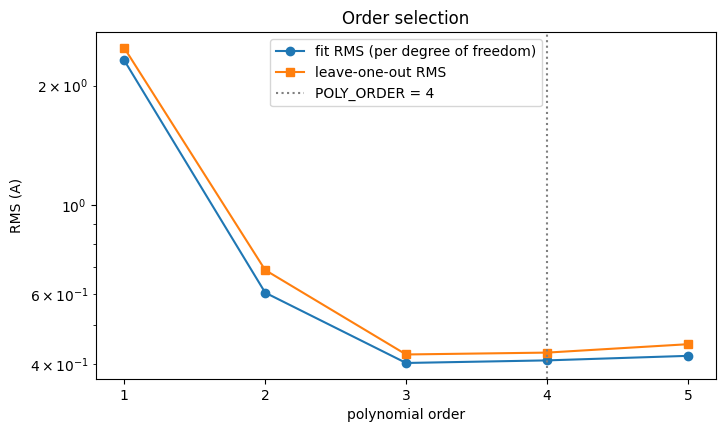

Suggested order: 3  (lowest order within 10% of the best leave-one-out RMS)
-> POLY_ORDER is currently 4; consider changing it in the parameter cell and rerunning.


In [ ]:
# ---- 11b. Order selection: fit RMS vs leave-one-out (diagnostic only) ----
ORDERS_TO_TEST = range(1, 6)

p_sel   = centroids[cen_i][used]     # pixel positions of the lines the final fit kept
lam_sel = catalog[cat_i][used]       # their catalog wavelengths
n_sel   = p_sel.size

# np.polynomial.Polynomial.fit rescales p to [-1, 1] internally, which keeps high orders
# numerically well-behaved. Fine here, because we only need predictions, not coefficients.
order_rows = []
for k in ORDERS_TO_TEST:
    n_coef = k + 1
    if n_sel - n_coef < 2:
        print(f'order {k}: skipped ({n_sel} lines is too few)')
        continue

    # fit RMS on all selected lines
    poly_k = np.polynomial.Polynomial.fit(p_sel, lam_sel, k)
    r_fit = lam_sel - poly_k(p_sel)
    rms_fit = np.sqrt(np.sum(r_fit**2) / (n_sel - n_coef))

    # leave-one-out: drop line j, fit the rest, predict line j
    r_loo = np.zeros(n_sel)
    for j in range(n_sel):
        keep = np.arange(n_sel) != j
        poly_j = np.polynomial.Polynomial.fit(p_sel[keep], lam_sel[keep], k)
        r_loo[j] = lam_sel[j] - poly_j(p_sel[j])
    rms_loo = np.sqrt(np.mean(r_loo**2))
    worst = np.argmax(np.abs(r_loo))

    order_rows.append((k, rms_fit, rms_loo, r_loo[worst], lam_sel[worst]))

print(f'{n_sel} lines used\n')
print(f'{"order":>5} {"fit RMS (A)":>12} {"LOO RMS (A)":>12} {"worst LOO (A)":>14}  at line')
for k, rf, rl, rw, lw in order_rows:
    print(f'{k:5d} {rf:12.4f} {rl:12.4f} {rw:14.4f}  {lw:.2f}')

ks       = np.array([r[0] for r in order_rows])
rms_fits = np.array([r[1] for r in order_rows])
rms_loos = np.array([r[2] for r in order_rows])

plt.figure(figsize=(8, 4.5))
plt.semilogy(ks, rms_fits, 'o-', label='fit RMS (per degree of freedom)')
plt.semilogy(ks, rms_loos, 's-', label='leave-one-out RMS')
plt.axvline(POLY_ORDER, color='gray', ls=':', label=f'POLY_ORDER = {POLY_ORDER}')
plt.xticks(ks); plt.xlabel('polynomial order'); plt.ylabel('RMS (A)')
plt.title('Order selection'); plt.legend()
plt.show()

# suggestion: lowest order whose LOO RMS is within 10% of the best one
best_loo = rms_loos.min()
suggested = ks[np.argmax(rms_loos <= 1.10 * best_loo)]
print(f'Suggested order: {suggested}  (lowest order within 10% of the best leave-one-out RMS)')
if suggested != POLY_ORDER:
    print(f'-> POLY_ORDER is currently {POLY_ORDER}; consider changing it in the parameter cell and rerunning.')

## 12. Sanity checks
This cell runs automated warnings for the usual ways a polynomial fit goes wrong. It's quiet when everything is fine.

In [ ]:
warnings_found = []

# 1. enough lines per free parameter
if used.sum() < 2 * (POLY_ORDER + 1):
    warnings_found.append(f'Only {used.sum()} lines for {POLY_ORDER + 1} coefficients; the fit is poorly constrained. '
                          'Consider a lower POLY_ORDER or more catalog lines.')

# 2. extrapolation beyond the outermost matched lines
p_lo, p_hi = centroids[cen_i][used].min(), centroids[cen_i][used].max()
edge_frac = ((p_lo - pix[0]) + (pix[-1] - p_hi)) / (pix[-1] - pix[0])
if edge_frac > 0.15:
    warnings_found.append(f'Matched lines only span pixels {p_lo:.0f}-{p_hi:.0f}; {100*edge_frac:.0f}% of the '
                          'detector is extrapolated, where a high-order polynomial can run away.')

# 3. dispersion must keep one sign across the whole detector (no fold-over)
dlam = np.diff(wavelength(pix))
if not (np.all(dlam > 0) or np.all(dlam < 0)):
    warnings_found.append('The solution is NOT monotonic across the detector; it is unphysical. Lower POLY_ORDER.')

# 4. RMS sanity
if rms > 0.5 * abs(D_guess):
    warnings_found.append(f'RMS ({rms:.3f} A) is more than half a pixel; suspect a wrong match or a bad order.')

if warnings_found:
    for w in warnings_found:
        print('WARNING:', w)
else:
    print('All checks passed.')
print(f'\nSolution covers {wavelength(pix[0]):.2f} .. {wavelength(pix[-1]):.2f} A; '
      f'dispersion {dlam.min():.4f} .. {dlam.max():.4f} A/px')

All checks passed.

Solution covers 3614.34 .. 7207.57 A; dispersion 2.5677 .. 2.6199 A/px


## 13. Visual check: calibrated lamp spectrum
The final test is by eye. Every red dashed catalog line should sit on top of a lamp line.

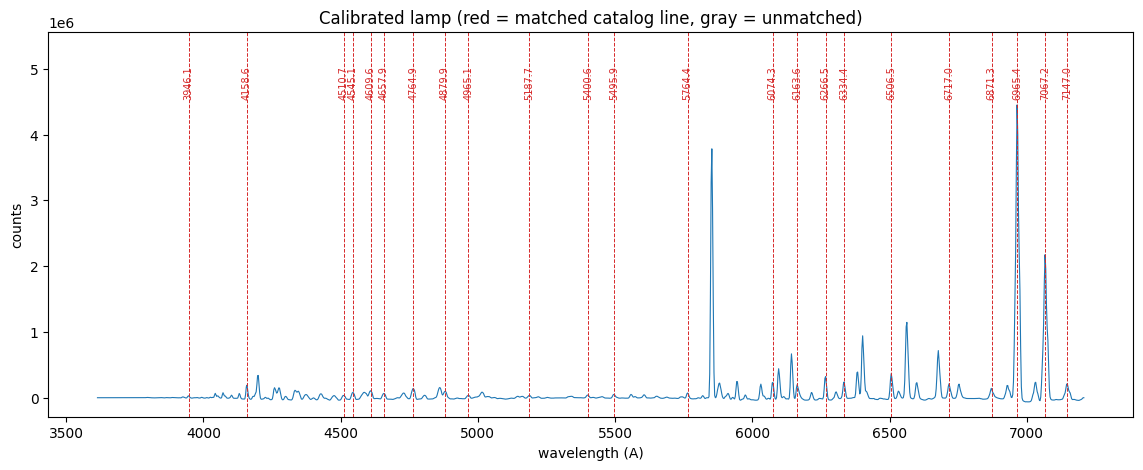

In [ ]:
lam_axis = wavelength(pix)
plt.figure(figsize=(14, 5))
plt.plot(lam_axis, flux_sub, lw=0.8)
for k, c in enumerate(catalog):
    col = 'C3' if k in cat_i else 'gray'
    plt.axvline(c, color=col, ls='--', lw=0.7)
    plt.text(c, np.max(flux_sub) * 1.02, f'{c:.1f}', rotation=90, fontsize=7, ha='center', va='bottom', color=col)
plt.xlabel('wavelength (A)'); plt.ylabel('counts')
plt.title('Calibrated lamp (red = matched catalog line, gray = unmatched)')
plt.ylim(top=np.max(flux_sub) * 1.25)
plt.show()

## 14. Coefficients for Demetra
Convention: **λ(p) = A₀ + A₁p + A₂p² + …**, with p starting at `PIXEL_ORIGIN`.

The coefficients are printed with full precision. Keep every digit, because the high-order terms multiply very large powers of p. The file `wavelength_solution.txt` is also written (and downloaded, in Colab).

If Demetra counts pixels from 1 and this was run with `PIXEL_ORIGIN = 0` (or vice versa), the coefficients will be *wrong* (shifted by one pixel). Just change `PIXEL_ORIGIN` and rerun.

In [ ]:
print(f'Pixel origin: {PIXEL_ORIGIN}   order: {POLY_ORDER}   RMS: {rms:.4f} A   lines used: {used.sum()}\n')
for k, a in enumerate(coeffs):
    print(f'A_{k} = {a:.12e}')

# spot values: easy to compare with what Demetra shows after you enter the coefficients
print('\nCheck values:')
for p_ in (pix[0], pix[n_pix // 2], pix[-1]):
    print(f'  lambda({p_}) = {wavelength(p_):.3f} A')

if DOWNLOAD_FLAG==1:
    out_name = 'wavelength_solution.txt'
    with open(out_name, 'w') as f:
        f.write(f'# lambda(p) = sum_k A_k p^k ; pixel origin = {PIXEL_ORIGIN}\n')
        f.write(f'# source = {FITS_FILE} ; lines used = {used.sum()} ; RMS = {rms:.4f} A\n')
        for k, a in enumerate(coeffs):
            f.write(f'A_{k} {a:.12e}\n')
    print(f'\nWritten to {out_name}')
    if IN_COLAB:
        colab_files.download(out_name)

Pixel origin: 0   order: 4   RMS: 0.4079 A   lines used: 23

A_0 = 3.614339856819e+03
A_1 = 2.567727314846e+00
A_2 = 8.497749761604e-06
A_3 = -3.390605993296e-09
A_4 = 4.494743249646e-12

Check values:
  lambda(0) = 3614.340 A
  lambda(695) = 5402.925 A
  lambda(1390) = 7207.572 A
